In [ ]:
# Libreria para cargar nuestro drive
from google.colab import drive
# Cargamos nuestro drive en nuestro notebook
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
# Ajusta esta ruta a la carpeta de Drive donde guardas los datos del proyecto.
PROJECT_DIR = "/content/drive/MyDrive/plant-disease-classification"

In [ ]:
!cp -r "{PROJECT_DIR}/PlantVillage" /content/

In [ ]:
import tensorflow as tf
import numpy as np
import random

seed = 42

tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)


En esta sección se realiza la preparación del dataset.
Se recorren las carpetas donde cada una representa una clase,
obteniendo las rutas de las imágenes y sus etiquetas.

Posteriormente, se organiza la información en un DataFrame
para facilitar su análisis y uso en el entrenamiento del modelo.


In [ ]:
import pandas as pd
import os

# Ruta principal del dataset (cada carpeta es una clase)
path_raiz = '/content/PlantVillage'

# Listas para guardar rutas de imágenes y sus etiquetas
filepaths = []
labels = []

# Recorremos cada carpeta (clase)
classlist = sorted(os.listdir(path_raiz))
for klass in classlist:
    classpath = os.path.join(path_raiz, klass)

    # Verificamos que sea una carpeta válida
    if os.path.isdir(classpath):
        flist = os.listdir(classpath)

        # Recorremos cada archivo dentro de la carpeta
        for f in flist:
            # Filtramos solo archivos de imagen
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                fpath = os.path.join(classpath, f)

                # Guardamos la ruta y la etiqueta (nombre de la carpeta)
                filepaths.append(fpath)
                labels.append(klass)

# Creamos el DataFrame con rutas y etiquetas
df = pd.DataFrame({'filepaths': filepaths, 'labels': labels})

# Mostramos información general del dataset
print(f"✅ DataFrame creado con éxito.")
print(f"Total de imágenes registradas: {len(df)}")

# Conteo por clase (útil para ver desbalanceo)
print("\nConteo por clase (aquí verás el desbalanceo):")
print(df['labels'].value_counts())


✅ DataFrame creado con éxito.
Total de imágenes registradas: 20638

Conteo por clase (aquí verás el desbalanceo):
labels
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Tomato_Early_blight                            1000
Pepper__bell___Bacterial_spot                   997
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Potato___healthy                                152
Name: count, dtype: int64


Se separaron los datos en 80% para entrenamiento y 20% para validación y prueba, manteniendo el balance de clases mediante stratify y asegurando resultados reproducibles con una semilla.

In [ ]:
from sklearn.model_selection import train_test_split

# 80% train, 20% temporal
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['labels'],
    random_state=42
)

# dividir ese 20% en val y test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['labels'],
    random_state=42
)

In [ ]:
print("TRAIN:\n", train_df['labels'].value_counts())
print("\nVAL:\n", val_df['labels'].value_counts())
print("\nTEST:\n", test_df['labels'].value_counts())

TRAIN:
 labels
Tomato__Tomato_YellowLeaf__Curl_Virus          2566
Tomato_Bacterial_spot                          1701
Tomato_Late_blight                             1527
Tomato_Septoria_leaf_spot                      1417
Tomato_Spider_mites_Two_spotted_spider_mite    1341
Tomato_healthy                                 1273
Pepper__bell___healthy                         1182
Tomato__Target_Spot                            1123
Potato___Late_blight                            800
Tomato_Early_blight                             800
Potato___Early_blight                           800
Pepper__bell___Bacterial_spot                   798
Tomato_Leaf_Mold                                762
Tomato__Tomato_mosaic_virus                     298
Potato___healthy                                122
Name: count, dtype: int64

VAL:
 labels
Tomato__Tomato_YellowLeaf__Curl_Virus          321
Tomato_Bacterial_spot                          213
Tomato_Late_blight                             191
Tomato_Septo

Se preparan los generadores de imágenes para el entrenamiento y validación.
Se normalizan los valores de los píxeles y se aplican técnicas de aumento
de datos para mejorar la generalización del modelo.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,        # Normaliza los píxeles (0–255 → 0–1)
    rotation_range=20,     # Rota imágenes hasta 20 grados
    zoom_range=0.2,        # Aplica zoom aleatorio
    horizontal_flip=True   # Voltea imágenes horizontalmente
)

val_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    seed=42
)

Found 16510 validated image filenames belonging to 15 classes.
Found 2064 validated image filenames belonging to 15 classes.


Se calculan pesos para cada clase con el fin de compensar el desbalanceo
del dataset, permitiendo que el modelo no favorezca a las clases con
mayor cantidad de imágenes.

In [ ]:
from sklearn.utils import class_weight
import numpy as np

classes = train_generator.classes

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(classes),
    y=classes
)

class_weights = dict(enumerate(class_weights))

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Input

num_classes = len(train_generator.class_indices)

model = Sequential()

# Entrada
model.add(Input(shape=(224,224,3)))

# Bloque 1
model.add(Conv2D(32, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 2
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 3
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 4
model.add(Conv2D(256, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

# Aplanar
model.add(Flatten())

# Capa densa
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))

# Salida
model.add(Dense(num_classes, activation='softmax'))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,830,607 (37.50 MB)

 Trainable params: 9,830,159 (37.50 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Se entrena el modelo utilizando los datos de entrenamiento y validación.
Se aplica EarlyStopping para detener el entrenamiento automáticamente
cuando el modelo deja de mejorar, evitando sobreajuste.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 4277s 8s/step - accuracy: 0.4078 - loss: 2.1495 - val_accuracy: 0.3895 - val_loss: 1.9809
Epoch 2/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 287s 557ms/step - accuracy: 0.5448 - loss: 1.4169 - val_accuracy: 0.3493 - val_loss: 3.2436
Epoch 3/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 284s 550ms/step - accuracy: 0.6339 - loss: 1.0863 - val_accuracy: 0.5770 - val_loss: 1.9630
Epoch 4/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 276s 535ms/step - accuracy: 0.6869 - loss: 0.9445 - val_accuracy: 0.6429 - val_loss: 1.3771
Epoch 5/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 286s 554ms/step - accuracy: 0.7290 - loss: 0.8130 - val_accuracy: 0.5276 - val_loss: 3.5972
Epoch 6/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 275s 533ms/step - accuracy: 0.7514 - loss: 0.7586 - val_accuracy: 0.7461 - val_loss: 0.9028
Epoch 7/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 280s 543ms/step - accuracy: 0.7700 - loss: 0.7067 - val_accuracy: 0.5426 - val_loss: 2.0147
Epoch 8/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 280s 543ms/step - accuracy: 0.8010 - l

Entrenamiento (2h 40min)


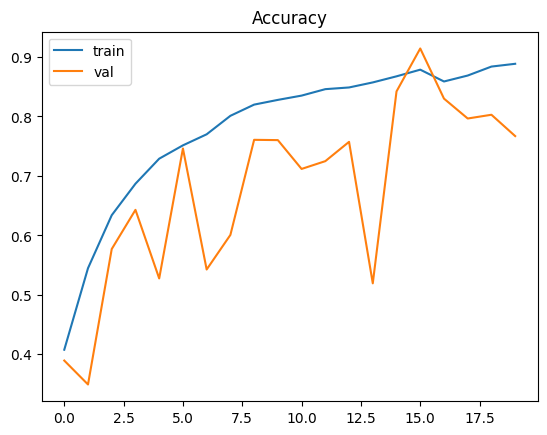

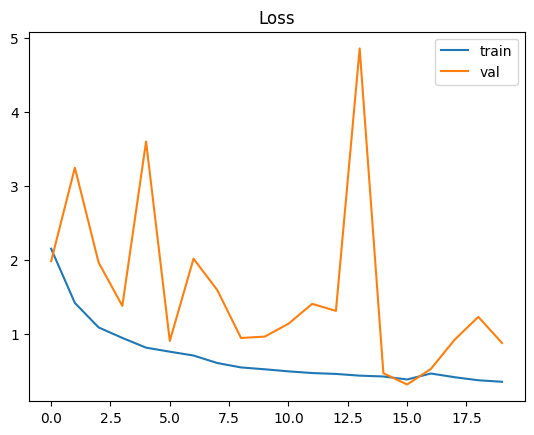

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

El modelo muestra un aprendizaje progresivo en el conjunto de entrenamiento, mientras que en validación presenta cierta inestabilidad. Sin embargo, no se observa un sobreajuste significativo, ya que ambas curvas se mantienen relativamente cercanas.

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

Found 2064 validated image filenames belonging to 15 classes.


In [ ]:
loss, acc = model.evaluate(test_generator)

print(f"Test Loss: {loss}")
print(f"Test Accuracy: {acc}")

65/65 ━━━━━━━━━━━━━━━━━━━━ 447s 7s/step - accuracy: 0.8968 - loss: 0.3272
Test Loss: 0.32722222805023193
Test Accuracy: 0.8968023061752319


In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

65/65 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

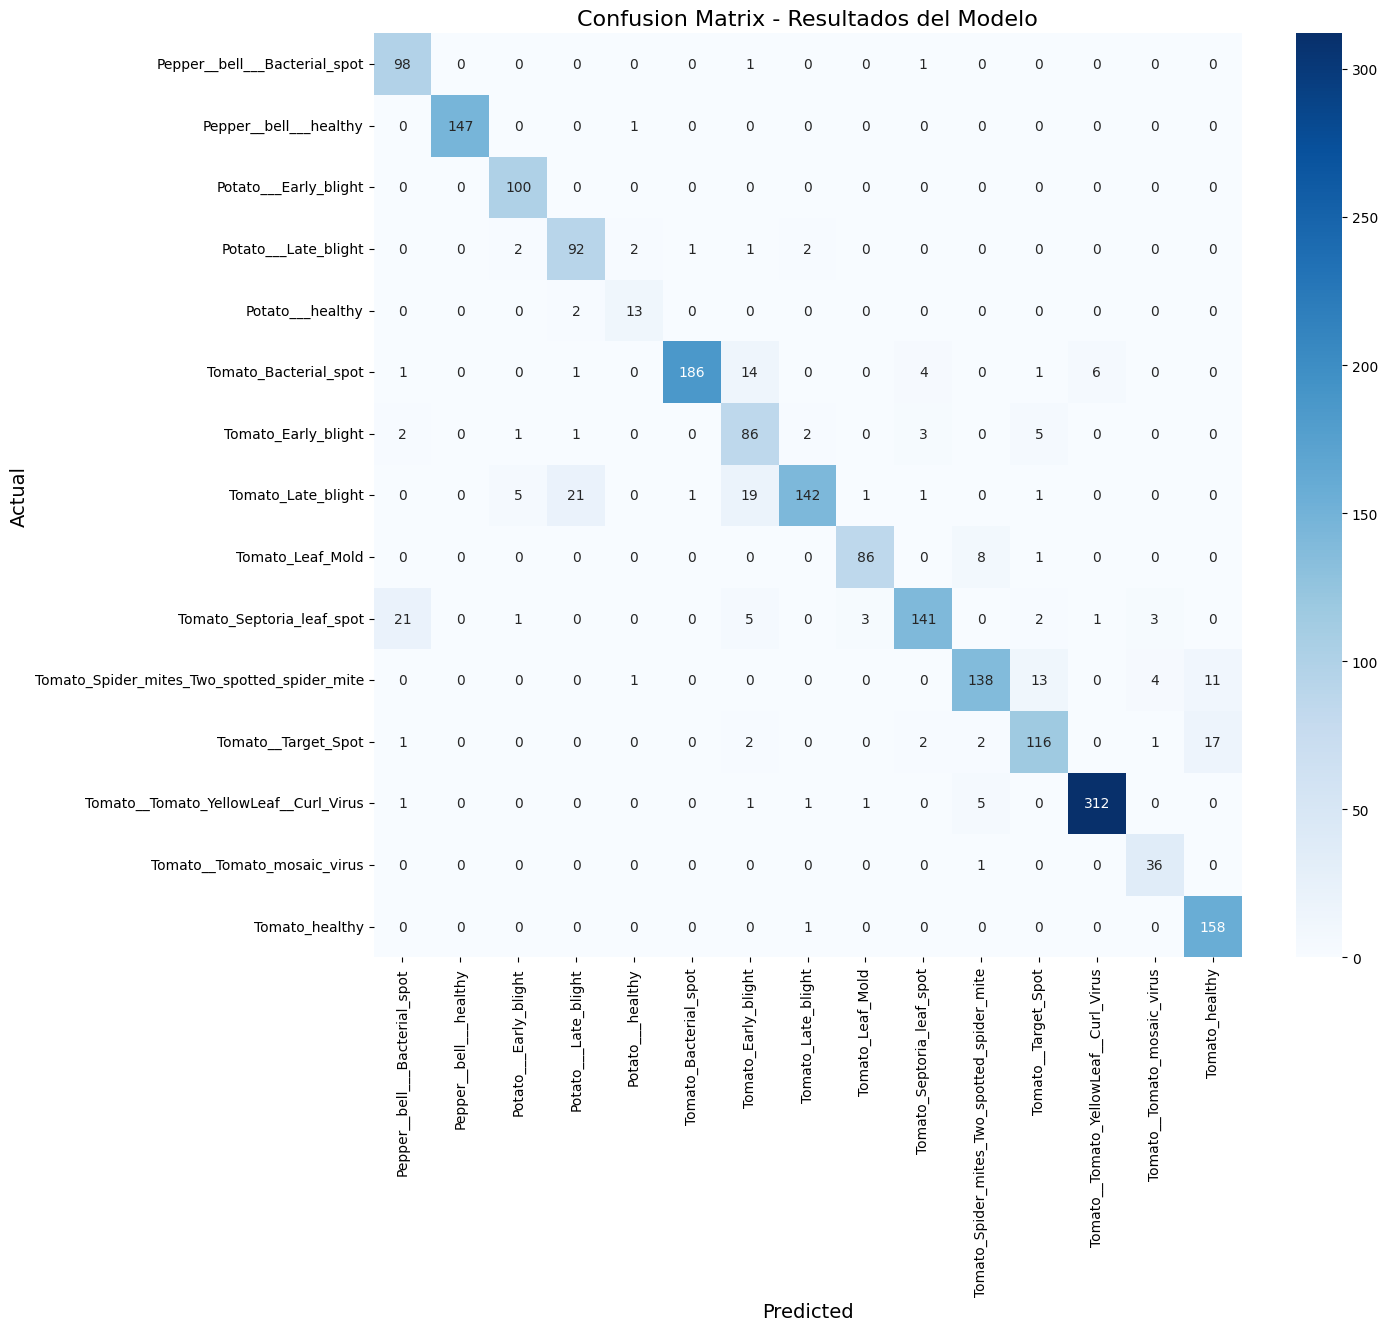

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generamos la matriz
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 10})

plt.xlabel("Predicted", fontsize=14)
plt.ylabel("Actual", fontsize=14)
plt.title("Confusion Matrix - Resultados del Modelo", fontsize=16)
plt.xticks(rotation=90) # Rota las etiquetas para que se lean bien
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.79      0.98      0.88       100
                     Pepper__bell___healthy       1.00      0.99      1.00       148
                      Potato___Early_blight       0.92      1.00      0.96       100
                       Potato___Late_blight       0.79      0.92      0.85       100
                           Potato___healthy       0.76      0.87      0.81        15
                      Tomato_Bacterial_spot       0.99      0.87      0.93       213
                        Tomato_Early_blight       0.67      0.86      0.75       100
                         Tomato_Late_blight       0.96      0.74      0.84       191
                           Tomato_Leaf_Mold       0.95      0.91      0.92        95
                  Tomato_Septoria_leaf_spot       0.93      0.80      0.86       177
Tomato_Spider_mites_Two_spotted_spider_mite       0.90      0.83

## 🔬 Experimento 2: Modelo DenseNet121



In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
IMG_SIZE = 224

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(IMG_SIZE, IMG_SIZE),
    class_mode='categorical',
    batch_size=32,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(IMG_SIZE, IMG_SIZE),
    class_mode='categorical',
    batch_size=32,
    seed=42
)

Found 16510 validated image filenames belonging to 15 classes.
Found 2064 validated image filenames belonging to 15 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Cargar modelo base (sin la parte final)
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

for layer in base_model.layers:
    layer.trainable = False


x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(len(train_generator.class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,303,759 (27.86 MB)

 Trainable params: 266,255 (1.02 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from sklearn.utils import class_weight
import numpy as np

classes = train_generator.classes

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(classes),
    y=classes
)

class_weights = dict(enumerate(class_weights))

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 295s 507ms/step - accuracy: 0.5970 - loss: 1.2367 - val_accuracy: 0.8266 - val_loss: 0.5349
Epoch 2/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 226s 438ms/step - accuracy: 0.7660 - loss: 0.6813 - val_accuracy: 0.8813 - val_loss: 0.4014
Epoch 3/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 223s 432ms/step - accuracy: 0.8057 - loss: 0.5471 - val_accuracy: 0.8866 - val_loss: 0.3474
Epoch 4/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 236s 457ms/step - accuracy: 0.8273 - loss: 0.4927 - val_accuracy: 0.8929 - val_loss: 0.3089
Epoch 5/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 229s 443ms/step - accuracy: 0.8331 - loss: 0.4727 - val_accuracy: 0.8987 - val_loss: 0.2830
Epoch 6/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 221s 428ms/step - accuracy: 0.8494 - loss: 0.4285 - val_accuracy: 0.9123 - val_loss: 0.2665
Epoch 7/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 231s 446ms/step - accuracy: 0.8525 - loss: 0.4098 - val_accuracy: 0.9239 - val_loss: 0.2383
Epoch 8/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 220s 426ms/step - accuracy: 0.8636 -

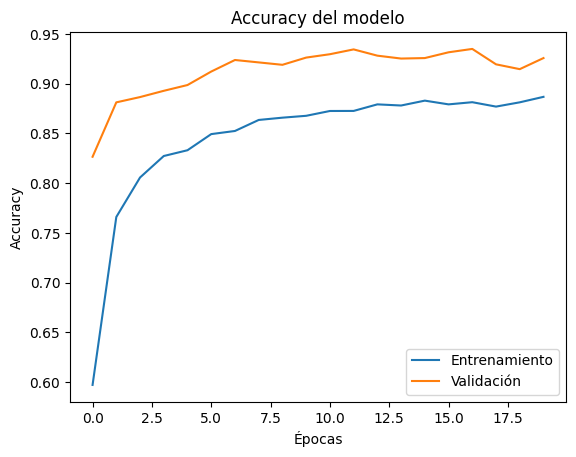

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Accuracy del modelo')
plt.ylabel('Accuracy')
plt.xlabel('Épocas')
plt.legend(['Entrenamiento', 'Validación'])

plt.show()

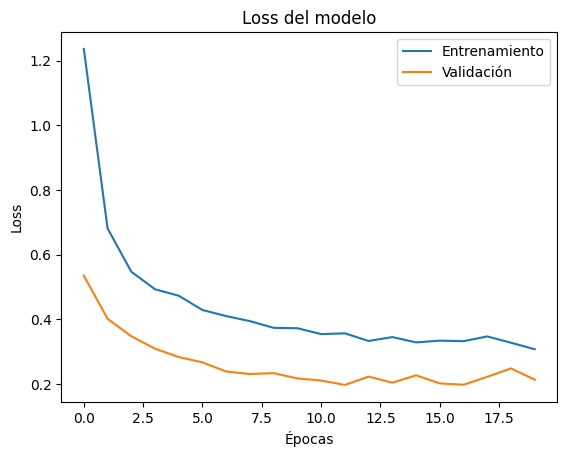

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Loss del modelo')
plt.ylabel('Loss')
plt.xlabel('Épocas')
plt.legend(['Entrenamiento', 'Validación'])

plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),  # igual que el modelo
    class_mode='categorical',
    batch_size=32,
    shuffle=False  # 🔥 MUY IMPORTANTE
)

Found 2064 validated image filenames belonging to 15 classes.


In [ ]:
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test accuracy: {test_acc}")
print(f"Test loss: {test_loss}")

65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.9264 - loss: 0.2086
Test accuracy: 0.9263566136360168
Test loss: 0.20856575667858124


In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

65/65 ━━━━━━━━━━━━━━━━━━━━ 30s 281ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

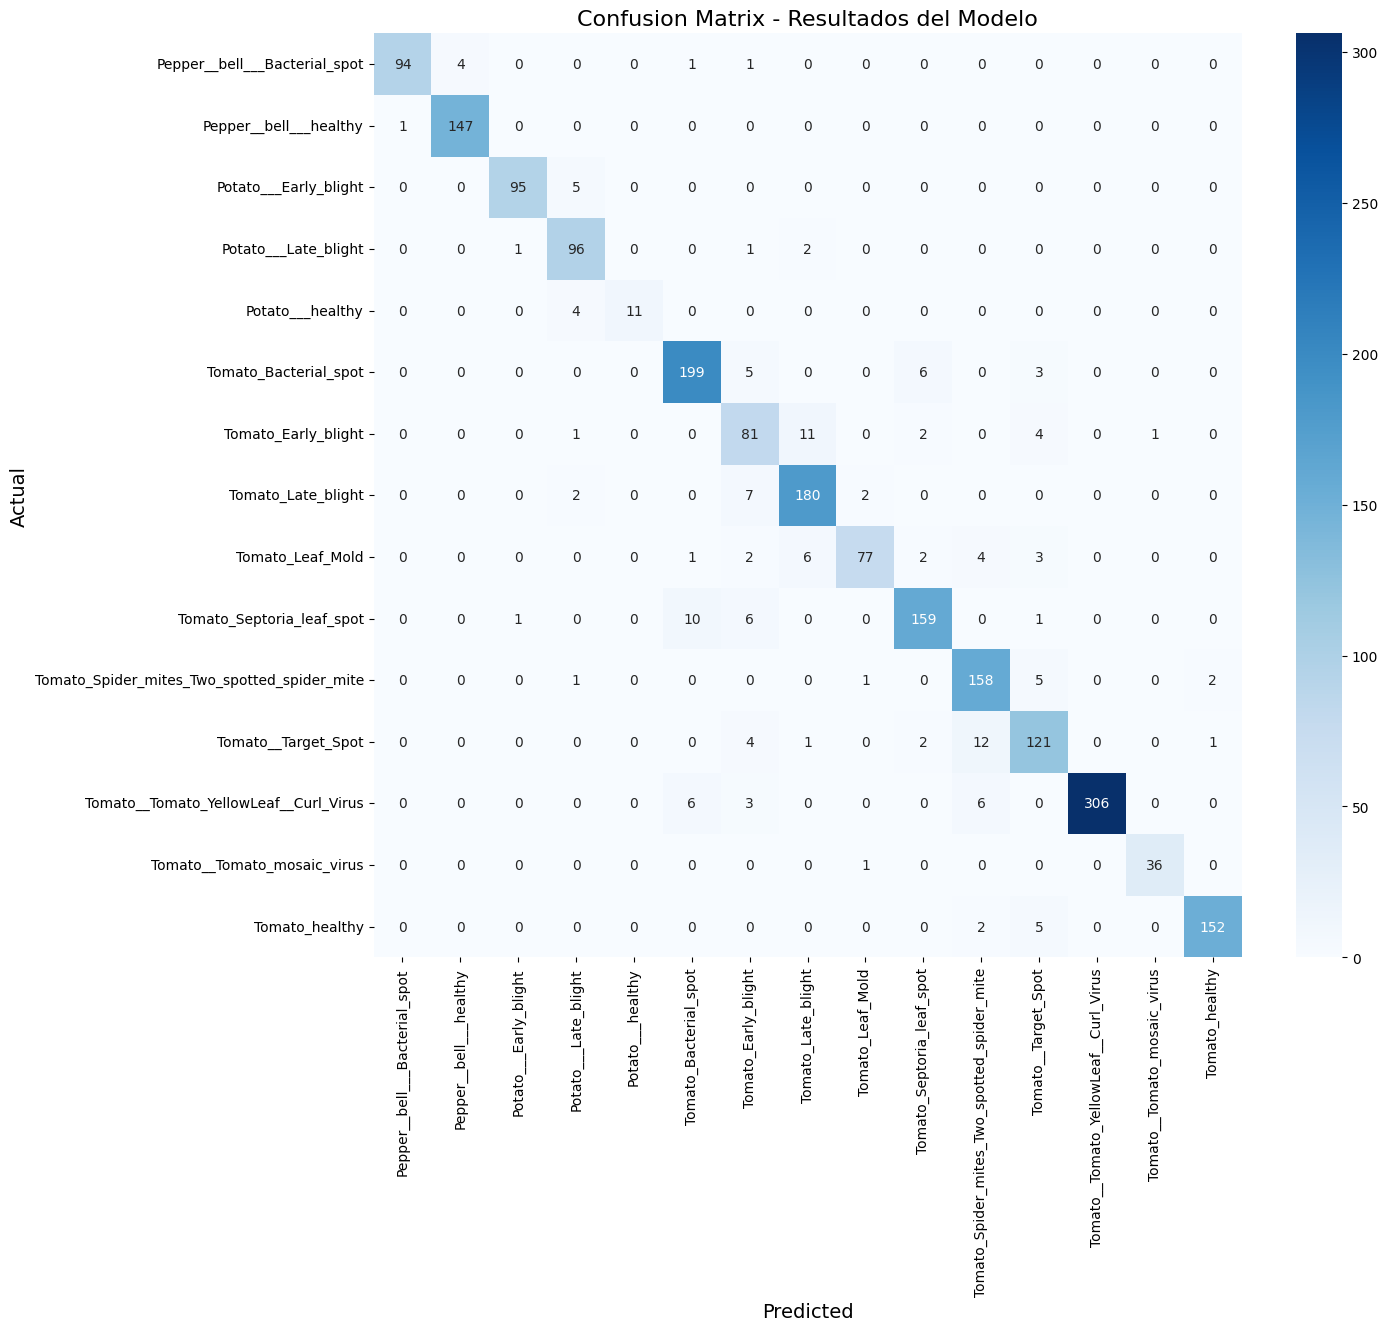

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generamos la matriz
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 10})

plt.xlabel("Predicted", fontsize=14)
plt.ylabel("Actual", fontsize=14)
plt.title("Confusion Matrix - Resultados del Modelo", fontsize=16)
plt.xticks(rotation=90) # Rota las etiquetas para que se lean bien
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.99      0.94      0.96       100
                     Pepper__bell___healthy       0.97      0.99      0.98       148
                      Potato___Early_blight       0.98      0.95      0.96       100
                       Potato___Late_blight       0.88      0.96      0.92       100
                           Potato___healthy       1.00      0.73      0.85        15
                      Tomato_Bacterial_spot       0.92      0.93      0.93       213
                        Tomato_Early_blight       0.74      0.81      0.77       100
                         Tomato_Late_blight       0.90      0.94      0.92       191
                           Tomato_Leaf_Mold       0.95      0.81      0.88        95
                  Tomato_Septoria_leaf_spot       0.93      0.90      0.91       177
Tomato_Spider_mites_Two_spotted_spider_mite       0.87      0.95